In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from dizx.circuit_extractor import to_stim
from dizx.realisation import RealisedSED
from dizx.schedules import RotatedSurfaceCodeSchedule
from dizx.surgery import two_patch_surgery

In [2]:
d = 3
matching = two_patch_surgery(d, "ZZ", rounds=(2, 2, 2))
standard = two_patch_surgery(d, "ZZ", rounds=(2, 2, 2), matching=False)
for name, s in (("matching", matching), ("standard", standard)):
    print(name, "merge rounds", list(s.merge_rounds), "ports", len(s.sed.inputs), len(s.sed.outputs),
          "complete", s.sed.webs_complete(), s.sed.detectors_complete())
    for p, v in sorted(s.sed.closed.items()):
        print("   ", p, "->", v, s.sed.types[v].value)

matching merge rounds [2, 3, 4] ports 18 18 complete True True
    ('in', (3, 0)) -> ('data', 2, 'Z', (3, 0)) Z
    ('in', (3, 1)) -> ('data', 2, 'Z', (3, 1)) Z
    ('in', (3, 2)) -> ('data', 2, 'Z', (3, 2)) Z
    ('out', (3, 0)) -> ('data', 4, 'Z', (3, 0)) Z
    ('out', (3, 1)) -> ('data', 4, 'Z', (3, 1)) Z
    ('out', (3, 2)) -> ('data', 4, 'Z', (3, 2)) Z
standard merge rounds [2, 3] ports 18 18 complete True True
    ('in', (3, 0)) -> ('data', 2, 'Z', (3, 0)) Z
    ('in', (3, 1)) -> ('data', 2, 'Z', (3, 1)) Z
    ('in', (3, 2)) -> ('data', 2, 'Z', (3, 2)) Z
    ('out', (3, 0)) -> ('proj', ('out', (3, 0))) Z
    ('out', (3, 1)) -> ('proj', ('out', (3, 1))) Z
    ('out', (3, 2)) -> ('proj', ('out', (3, 2))) Z


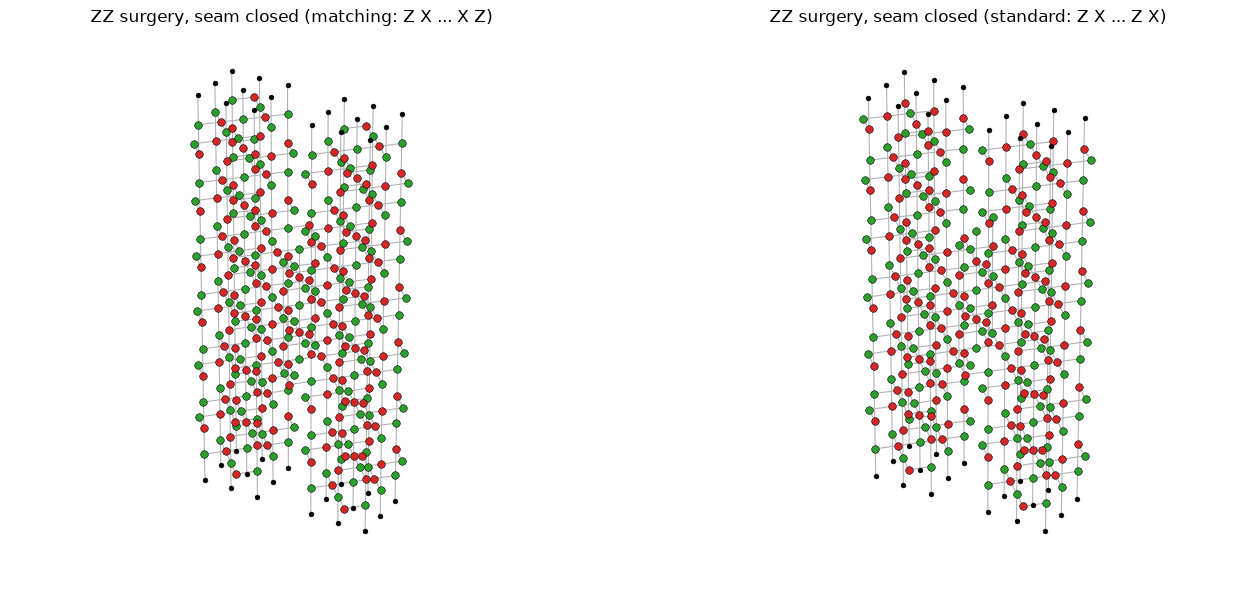

In [3]:
fig = plt.figure(figsize=(16, 8))
for k, (name, s) in enumerate((("matching: Z X ... X Z", matching), ("standard: Z X ... Z X", standard))):
    (s.sed.draw(ax=fig.add_subplot(1, 2, k + 1, projection="3d"), title=f"ZZ surgery, seam closed ({name})"))
plt.show()

In [4]:
sed = matching.sed
starts = {v for p, v in sed.closed.items() if p[0] == "in"}
seam_start_dets = [w for w in sed.detectors
                   if any(set(e[:2]) & starts for e in w.support())]
len(seam_start_dets)

6

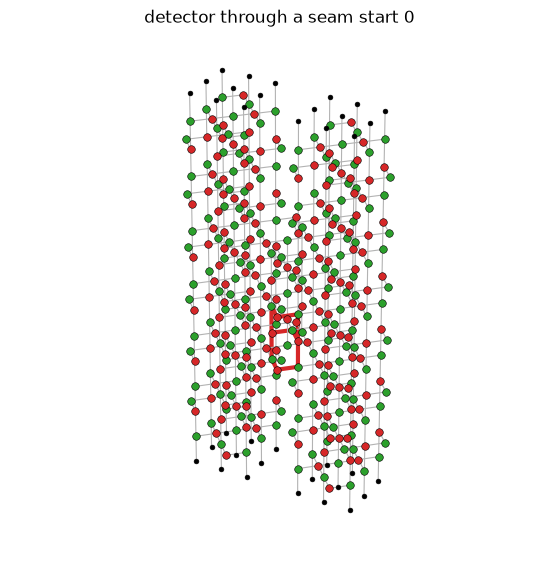

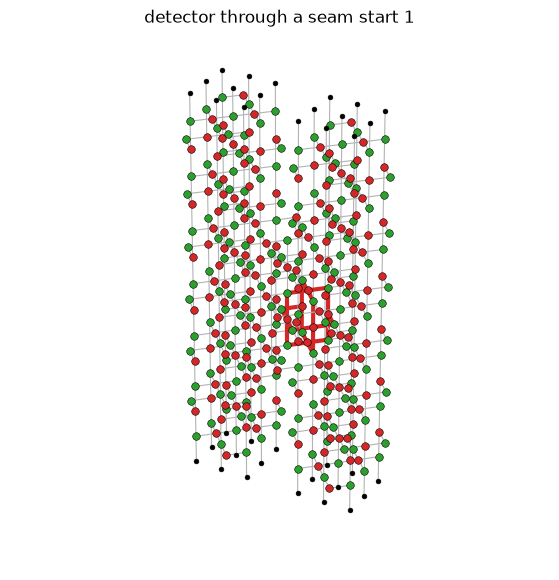

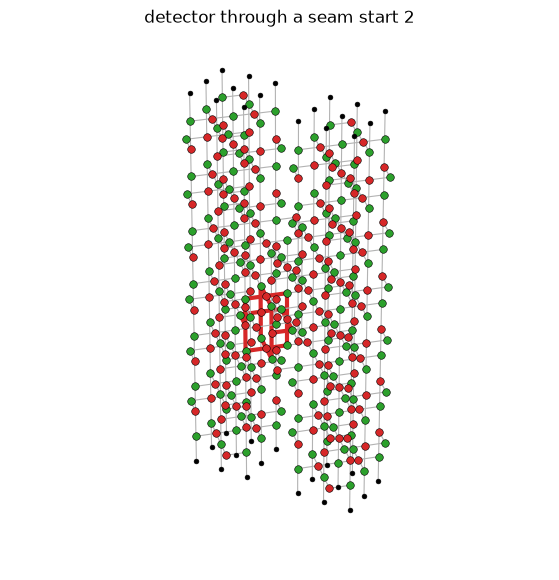

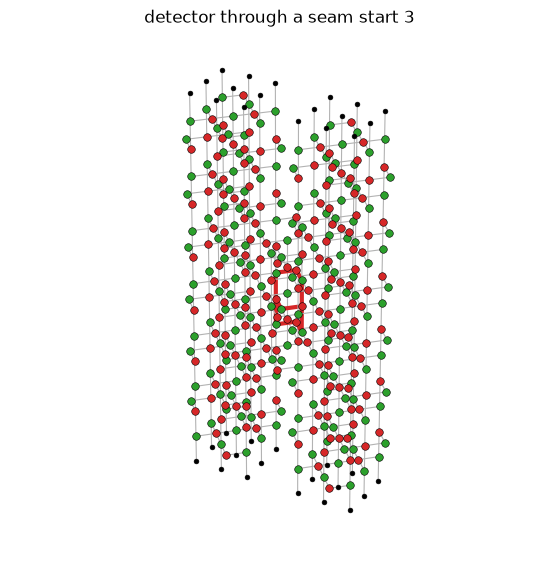

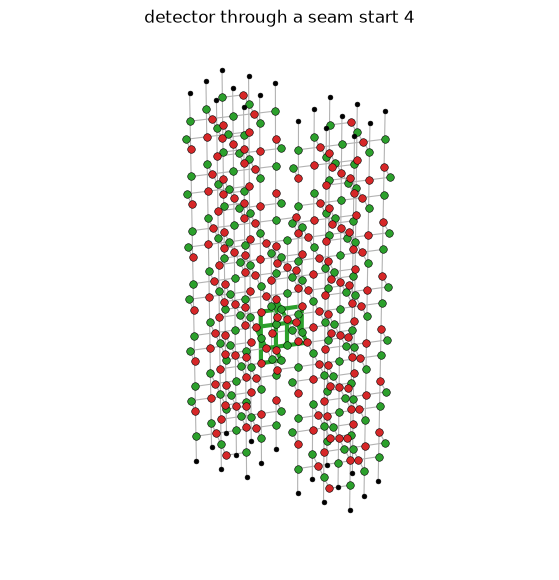

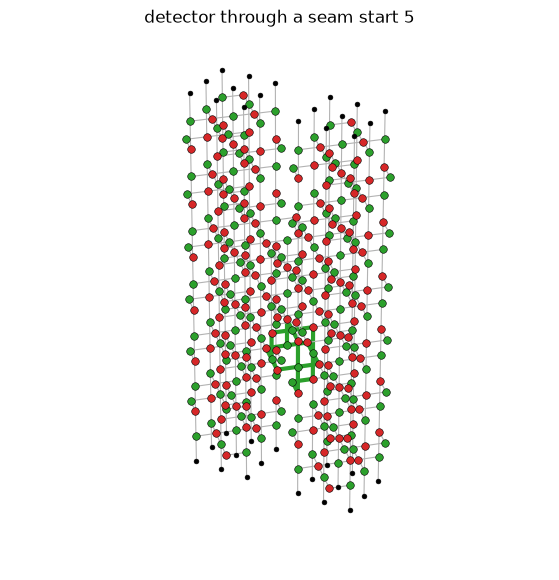

In [5]:
for k, w in enumerate(seam_start_dets):
    (sed.draw(w, title=f"detector through a seam start {k}"))
    plt.show()

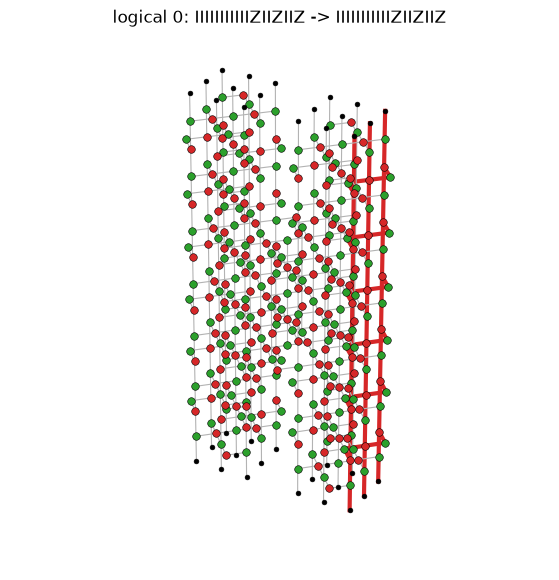

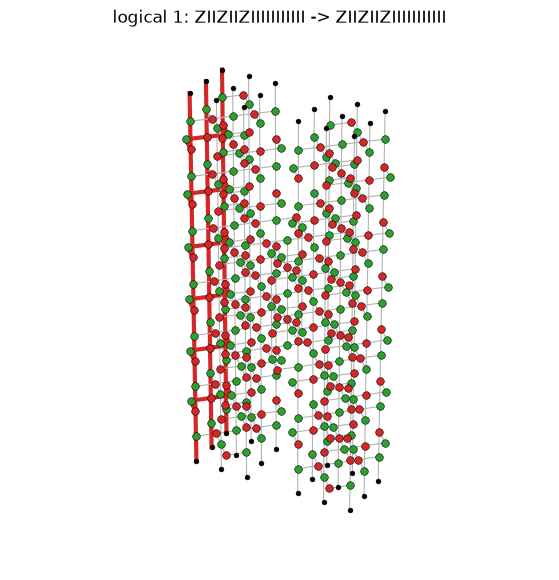

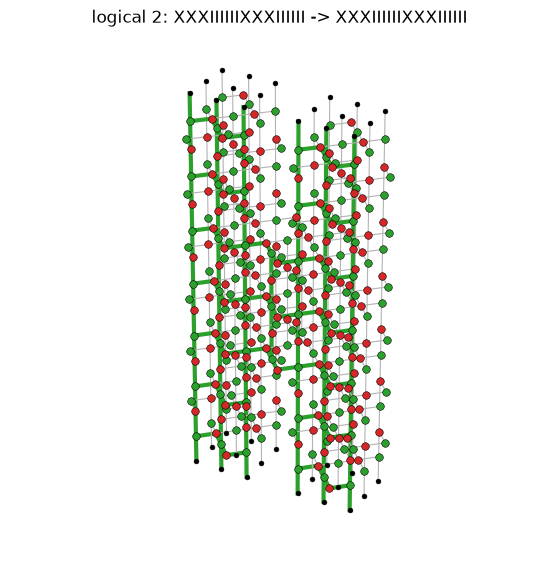

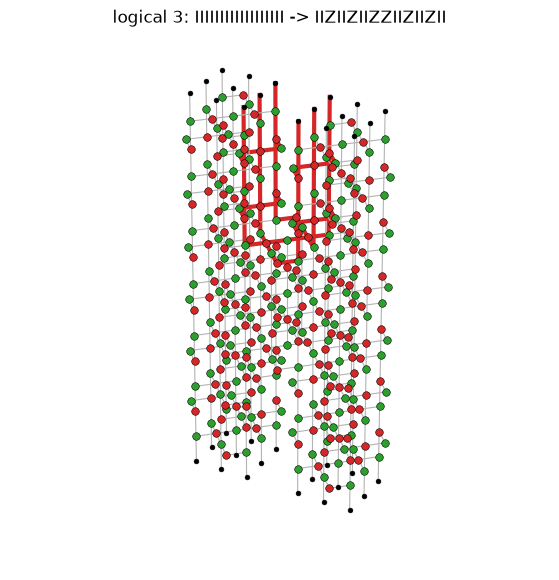

In [6]:
for k, w in enumerate(sed.logicals):
    sed.draw(w, title=f"logical {k}: {w.boundary()[0]} -> {w.boundary()[1]}")
    plt.show()

In [7]:
real = RealisedSED.circuit_based(matching.sed)
seam_ends = [v for p, v in matching.sed.closed.items() if p[0] == "out"]
[(v, real.classical.get(v)) for v in seam_ends]

[(('data', 4, 'Z', (3, 0)), ('meas', ('data', 4, 'Z', (3, 0)))),
 (('data', 4, 'Z', (3, 1)), ('meas', ('data', 4, 'Z', (3, 1)))),
 (('data', 4, 'Z', (3, 2)), ('meas', ('data', 4, 'Z', (3, 2))))]

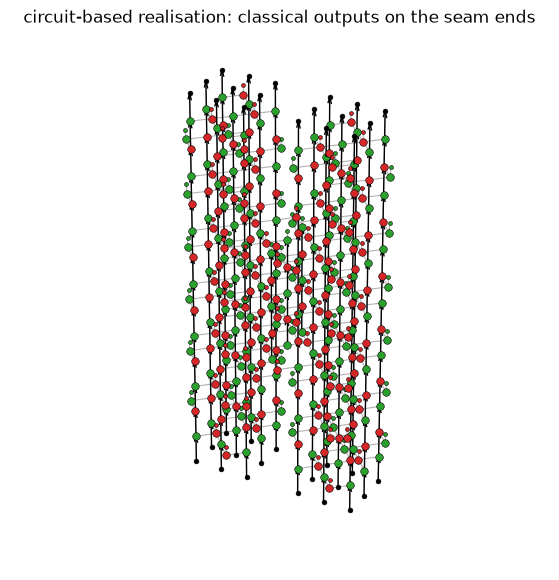

In [8]:
(real.draw(title="circuit-based realisation: classical outputs on the seam ends"))
plt.show()

In [9]:
exp = matching.experiment("Z")
circuit = to_stim(exp, RotatedSurfaceCodeSchedule(matching.merged))
coords = circuit.get_final_qubit_coordinates()
seam_qubits = sorted(q for q, c in coords.items() if c[0] == d and c[1] in (0, 1, 2))
seam_ops = [(inst.name, [t.qubit_value for t in inst.targets_copy() if t.qubit_value in seam_qubits])
            for inst in circuit.flattened() if inst.name in ("R", "RX", "M", "MX")]
[op for op in seam_ops if op[1]]

[('RX', [34, 35, 36]), ('MX', [34, 35, 36])]

In [10]:
xx = two_patch_surgery(d, "XX", rounds=(2, 2, 2), matching=False)
sorted((p, v, xx.sed.types[v].value) for p, v in xx.sed.closed.items())

[(('in', (3, 0)), ('init', ('in', (3, 0))), 'X'),
 (('in', (3, 1)), ('init', ('in', (3, 1))), 'X'),
 (('in', (3, 2)), ('init', ('in', (3, 2))), 'X'),
 (('out', (3, 0)), ('data', 3, 'X', (3, 0)), 'X'),
 (('out', (3, 1)), ('data', 3, 'X', (3, 1)), 'X'),
 (('out', (3, 2)), ('data', 3, 'X', (3, 2)), 'X')]

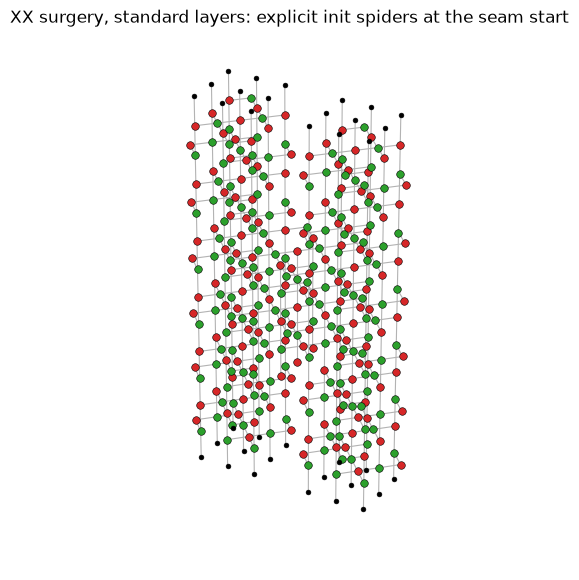

In [11]:
(xx.sed.draw(title="XX surgery, standard layers: explicit init spiders at the seam start"))
plt.show()